<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QBoost_BatterySOH_Akash2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBoost on a quantum-annealing sampler for battery health monitoring under adversarial attack: Akash, Khot and Kim (2023) step by step

This notebook re-implements, runs and checks the method of

> Alve Rahman Akash, Amey Khot and Taesic Kim, "Quantum Annealing-Based Machine Learning for Battery Health Monitoring Robust to Adversarial Attacks",
> *2023 IEEE Energy Conversion Congress and Exposition (ECCE)*, pp. 6307-6311, IEEE, 2023. DOI 10.1109/ECCE53617.2023.10362215

The paper publishes no code. Everything below is written from the five-page description.

**What the notebook does.** It downloads real cycling data of two commercial 18650 NMC lithium-ion cells from the Sandia National
Laboratories battery-degradation study (Preger et al., 2020, the data source the paper names), cuts every charge / rest / discharge
sequence out of the raw spreadsheets, computes the five features the paper lists (recovery voltage, discharge capacity, Shannon
entropy, kurtosis, skewness), and trains a **QBoost regressor**: 80 decision-tree weak regressors whose binary weights are chosen by
solving a QUBO problem (Eq. 1-4). The paper solves the QUBO on a D-Wave Advantage annealer; no annealer is reachable from a notebook, so the
identical QUBO is solved here with the simulated-annealing sampler of D-Wave's open-source `dwave-samplers` package. The ensemble is
compared with a random forest on exactly the same inputs, first on normal test data and then under a Gaussian-random feature attack,
and every number is put next to the paper's Table I.

**How to run.** In Google Colab choose a CPU runtime and *Run all* (set `FAST_MODE = True` in the configuration cell for a short class demo).
The first run downloads about 190 MB of spreadsheets from GitHub and extracts the features once (a few minutes); later runs reuse the small
cache in `DATA_DIR`. Nothing needs a token or an account.

**What you get at the end.** The data explored and plotted, the QUBO built and checked against an exact solver, the paper's Table I and
Figures 4 and 5 re-computed, a robustness curve over attack strengths, an ablation without the discharge-capacity feature, and a claim by
claim verdict against the paper.

## The paper in one page

**Problem.** A state-of-health (SOH) estimator for electric-vehicle batteries is a machine-learning model fed with sensor features. An attacker who
can alter the raw sensor stream or the extracted features can push the estimate away from the truth while staying stealthy
(an *adversarial* attack). The paper asks whether a model trained with quantum annealing is more robust than a random forest.

**Decision.** A regression, not a classification: the SOH of the cell (capacity relative to the new cell) at every charging cycle.

**Method.** *QBoost* (Neven et al., 2012) turns ensemble learning into an optimisation over binary weights $w_i \in \{0,1\}$ of $N$ weak regressors
$h_i$ (decision trees, Eq. 1). The loss is the squared error of the weighted ensemble (Eq. 2-3); choosing the weights is a quadratic unconstrained
binary optimisation (QUBO, Eq. 4), the form a quantum annealer accepts. The pipeline (Fig. 2-3): features from raw data -> grid-search CV of the tree
hyper-parameters (criterion, maximum depth, minimum samples per split and per leaf) -> train the weak trees on subsets of the training data -> QUBO
formulation -> D-Wave sampler -> normalise the boosted result -> SOH estimate. The paper uses 80 qubits (= 80 weak regressors) on a D-Wave Advantage.

**Data.** Cycling data of Li-ion cells from Preger et al. (J. Electrochem. Soc. 167, 120532, 2020; Sandia National Laboratories). Features follow Roman et al.
(Nature Machine Intelligence, 2021): recovery voltage, discharge capacity, Shannon entropy, kurtosis and skewness.

**Attack.** A *Gaussian random black-box attack* (Qin et al., NeurIPS 2021): random noise is added to the feature inputs of the model at test time. The paper
gives no noise magnitude.

**Claims (Table I, Fig. 4, Fig. 5 and the text).**

| Metric | RF, normal | QBoost, normal | RF, attacked | QBoost, attacked |
|---|---|---|---|---|
| R2 | 98.59 % | 91.30 % | 81.68 % | 84.99 % |
| MAE | 0.408 | 0.951 | 1.717 | 1.362 |
| MAPE | 0.487 | 1.163 | 2.036 | 1.596 |
| RMSE | 0.574 | 1.422 | 2.068 | 1.885 |

In words: the random forest is more accurate on normal data, QBoost is more robust under the attack; the optimal number of weak regressors is 80;
QBoost is accurate until about the 290th cycle (SOH margin 0.85) and makes larger errors at low SOH (after about 400 cycles).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Cells | "experimental data in [22]" (Preger et al.), cell not named | the two NMC cells that the Sandia / BatteryArchive GitHub repository publishes without login: NMC a and NMC b, 35 C, 0-100 % state of charge, 0.5 C charge / 1 C discharge |
| Train / test | not stated | train on one cell, test on the other (both directions), so the test cell is never seen in training |
| SOH definition | capacity ratio, 0.75-1 in the figures | discharge capacity of a cycle divided by the median of the first five regular cycles of the same cell |
| Cycles used | about 500 | all regular 1 C cycles of the cell (about 745); the slow reference-performance cycles are skipped |
| Features | recovery voltage, discharge capacity, Shannon entropy, kurtosis, skewness | exactly these five, defined in Section 2 (the paper does not give formulas) |
| Weak regressors | decision trees, 80 | 80 `DecisionTreeRegressor`, each trained on a random 40 % subset of the training cycles |
| Tree hyper-parameters | grid-search CV | `GridSearchCV` with contiguous 25-cycle blocks as groups so that neighbouring cycles do not leak across folds |
| QUBO | Eq. 1-4, not written out | squared loss + $\lambda$ per selected tree; $\lambda$ chosen on held-out training blocks |
| Solver | D-Wave Advantage 5000Q | `dwave.samplers.SimulatedAnnealingSampler` (classical), checked against an exact solver |
| Normalisation | "normalizing boosted results" | divide the weighted sum by the number of selected trees |
| Random forest | RF of [21], settings unknown | `RandomForestRegressor` with 80 trees and the same tuned tree hyper-parameters (criterion, depth, minimum samples per split and leaf) |
| Attack | Gaussian random noise, size unknown | noise with standard deviation $\sigma$ times the training standard deviation of each feature; $\sigma$ calibrated on training data only (Section 5) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, openpyxl and matplotlib.
# The pip line runs on Colab (or wherever dimod / dwave-samplers are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("dimod") is None or importlib.util.find_spec("dwave.samplers") is None:
    %pip install -q "dimod==0.12.22" "dwave-samplers==1.8.0"
    print("dimod and dwave-samplers installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("dimod and dwave-samplers already present; skipping pip install.")

dimod and dwave-samplers already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: 3 seeds, small grids, about 10 minutes. False: 10 seeds, full grids, longer annealing (about 40-60 minutes).
SEED      = 42              # CHOICE: the paper gives no seed
DATA_DIR  = "qc302_data"    # cache for the downloaded spreadsheets and the extracted per-cycle features
DWAVE_TOKEN = ""            # optional D-Wave Leap token; the cell in Section 3 that would use it is skipped when empty (never tested here)

N_WEAK       = 80           # paper: 80 qubits = 80 weak regressors
SUBSET_FRAC  = 0.4          # CHOICE: each tree sees a random 40 % of the training cycles ("training set split into subsets")
BLOCK        = 25           # CHOICE: contiguous blocks of 25 cycles are the unit for cross-validation groups and for the validation split
VAL_EVERY    = 5            # CHOICE: every 5th block (20 % of the cycles) of the training cell is held out for lambda and sigma
PAPER_RF_ATTACK_R2 = 81.68  # paper Table I; used ONLY to set the attack strength sigma on training-cell validation data (Section 5)

if FAST_MODE:
    SEEDS      = [42, 43, 44]
    ABL_SEEDS  = [42]                                   # seeds for the ablation without discharge capacity
    NOISE_REPS = 5                                      # noise draws per evaluation
    READS, SWEEPS = 60, 500                             # annealing reads and sweeps per QUBO
    LAM_GRID   = [0.0, 1e-3, 6e-3, 1e-2, 1.5e-2]        # CHOICE: sparsity penalty per selected tree
    DT_GRID    = dict(criterion=["squared_error"], max_depth=[3, 5, 8, None], min_samples_leaf=[1, 3, 5], min_samples_split=[2, 5, 10])
    SIGMA_SWEEP = [0.0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
else:
    SEEDS      = list(range(42, 52))
    ABL_SEEDS  = [42, 43, 44]
    NOISE_REPS = 20
    READS, SWEEPS = 150, 1000
    LAM_GRID   = [0.0, 1e-3, 3e-3, 6e-3, 1e-2, 1.5e-2]
    DT_GRID    = dict(criterion=["squared_error", "absolute_error"], max_depth=[3, 5, 8, None],
                      min_samples_leaf=[1, 3, 5], min_samples_split=[2, 5, 10])
    SIGMA_SWEEP = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0]
FEATS = ["recovery_voltage", "discharge_capacity", "shannon_entropy", "kurtosis", "skewness"]   # the paper's five features
print(f"FAST_MODE={FAST_MODE}, seeds={SEEDS}, reads={READS}, sweeps={SWEEPS}")

FAST_MODE=False, seeds=[42, 43, 44, 45, 46, 47, 48, 49, 50, 51], reads=150, sweeps=1000


In [3]:
import os, io, time, json, zipfile, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import requests, openpyxl, scipy, sklearn, dimod
from scipy.stats import skew, kurtosis
import dwave.samplers
from dwave.samplers import SimulatedAnnealingSampler, TabuSampler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("dimod", dimod.__version__, "| dwave-samplers", dwave.samplers.__version__, "| openpyxl", openpyxl.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
dimod 0.12.22 | dwave-samplers 1.8.0 | openpyxl 3.1.5


## 1. The data: two Sandia NMC cells from the Preger et al. degradation study

Preger et al. (2020) cycled 86 commercial 18650 cells (NMC, NCA and LFP chemistry) at different temperatures, depth-of-discharge windows and currents, and
published the raw tester files. The paper cites this study as its data source but does not say which cells it used. BatteryArchive.org (Sandia's public
archive) is a database front end; its GitHub repository `battery-lcf/battery-archive-sandbox` ships the raw Arbin spreadsheets of **two** of those cells as
plain zip files, without login or access gate: `SNL_18650_G5_NMC1.zip` (cell *a*) and `SNL_18650_G5_NMC2.zip` (cell *b*), both 3 Ah NMC/graphite cells cycled at
35 C between 0 % and 100 % state of charge with a 0.5 C charge (1.5 A, then constant voltage at 4.2 V) and a 1 C discharge (3 A down to 2.0 V). Each zip holds five
spreadsheets in chronological order. Every 100 or so cycles the schedule inserts slow *reference performance tests* (C/2 and C/20 discharges); these are not
regular cycles and are skipped.

The raw files are big (about 95 MB per zip, 20-30 MB per spreadsheet), so the cell below reads every spreadsheet once, keeps only the five columns it needs, extracts one
row of features per regular cycle (definitions in Section 2) plus the constant-current charging voltage curve, saves both to `DATA_DIR`, and then **deletes the zips and
spreadsheets**. On later runs only the small cache is read. If you downloaded the two zips yourself, put them into `DATA_DIR/snl/` and the download is skipped.

In [4]:
SNL_FILES = {"NMC1": "SNL_18650_G5_NMC1.zip", "NMC2": "SNL_18650_G5_NMC2.zip"}
URLS = ["https://raw.githubusercontent.com/battery-lcf/battery-archive-sandbox/main/data/snl/{f}",
        "https://github.com/battery-lcf/battery-archive-sandbox/raw/main/data/snl/{f}",
        "https://media.githubusercontent.com/media/battery-lcf/battery-archive-sandbox/main/data/snl/{f}"]
SNL_DIR = os.path.join(DATA_DIR, "snl"); os.makedirs(SNL_DIR, exist_ok=True)
FEATURE_CSV = os.path.join(DATA_DIR, "cycle_features.csv")
CURVE_NPZ = os.path.join(DATA_DIR, "cc_curves.npz")
V_LO, V_HI, N_BINS, N_GRID = 3.0, 4.2, 20, 200       # CHOICE: fixed histogram range / bins for the Shannon entropy; 200-point time grid per charge

def download(fname):
    path = os.path.join(SNL_DIR, fname)
    if os.path.exists(path) and os.path.getsize(path) > 5e7:
        return path
    for url in URLS:
        try:
            with requests.get(url.format(f=fname), stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path, "wb") as fh:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        fh.write(chunk)
            if os.path.getsize(path) > 5e7:
                return path
        except Exception as e:
            print("  download failed from", url.split("/")[2], "->", repr(e)[:100])
    raise RuntimeError(f"Could not download {fname}; put it into {SNL_DIR} by hand (BatteryArchive / battery-lcf/battery-archive-sandbox).")

def parse_file(path):
    """Read the 'Channel_*' sheet of one Arbin spreadsheet; keep only the five columns needed."""
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    name = [w.title for w in wb.worksheets if w.title.startswith("Channel_") and "Chart" not in w.title][0]
    rows = wb[name].iter_rows(values_only=True)
    hdr = next(rows)
    cols = ["Step_Index", "Step_Time(s)", "Current(A)", "Voltage(V)", "Discharge_Capacity(Ah)"]
    idx = [hdr.index(c) for c in cols]
    df = pd.DataFrame([[r[i] for i in idx] for r in rows], columns=cols)
    wb.close()
    return df

def runs_of(df):
    """Split a file into runs of consecutive rows with the same Step_Index (a new run also starts when Step_Time restarts)."""
    st = df["Step_Index"].to_numpy(); tt = df["Step_Time(s)"].to_numpy(float)
    new = np.r_[True, (st[1:] != st[:-1]) | (tt[1:] < tt[:-1])]
    return np.cumsum(new) - 1

def classify(I, V):
    mi = np.median(I)
    if len(I) >= 10 and -3.2 < mi < -2.8 and V[-1] < 2.05:
        return "D1C"                                                       # 1 C discharge (3 A) down to 2.0 V
    if len(I) >= 10 and 1.4 < np.median(I[:5]) < 1.6 and np.median(I[-3:]) > 1.4 and V[-1] > 4.15:
        return "CC"                                                        # 0.5 C constant-current charge (1.5 A) up to 4.2 V
    if abs(mi) < 0.05:
        return "REST"
    if V.mean() > 4.15 and I[0] > 0.2 and I[-1] < I[0]:
        return "CV"                                                        # constant-voltage charge at 4.2 V
    return "other"

def regular_blocks(df):
    """One feature dict (and the CC voltage curve) for every complete regular cycle: CC charge, CV charge, rest, 1 C discharge."""
    rid = runs_of(df)
    I = df["Current(A)"].to_numpy(float); V = df["Voltage(V)"].to_numpy(float)
    T = df["Step_Time(s)"].to_numpy(float); QD = df["Discharge_Capacity(Ah)"].to_numpy(float)
    b = np.flatnonzero(np.r_[True, rid[1:] != rid[:-1], True])
    runs = [(b[k], b[k + 1]) for k in range(len(b) - 1)]
    kinds = [classify(I[a:z], V[a:z]) for a, z in runs]
    out, curves = [], []
    for k in range(3, len(runs)):
        if kinds[k] == "D1C" and kinds[k - 1] == "REST" and kinds[k - 2] == "CV" and kinds[k - 3] == "CC":
            (a, z), (c0, c1), (r0, r1), (d0, d1) = runs[k - 3], runs[k - 2], runs[k - 1], runs[k]
            tc, vc = T[a:z], V[a:z]
            if not np.all(np.diff(tc) >= 0):
                continue
            grid = np.linspace(tc.min(), tc.max(), N_GRID)
            vg = np.interp(grid, tc, vc)                                   # CHOICE: time-uniform resampling of the CC charge voltage
            hist, _ = np.histogram(vg, bins=N_BINS, range=(V_LO, V_HI))
            p = hist / hist.sum(); p = p[p > 0]
            out.append(dict(discharge_capacity=float(QD[d1 - 1] - QD[d0]),            # Ah delivered in the 1 C discharge
                            recovery_voltage=float(V[c1 - 1] - V[r1 - 1]),            # relaxation of the terminal voltage during the 10-min rest after charge
                            shannon_entropy=float(-(p * np.log(p)).sum()),
                            kurtosis=float(kurtosis(vg)), skewness=float(skew(vg)),   # of the CC-charge voltage samples
                            cc_time=float(tc.max() - tc.min()), v_start_cc=float(vc[0])))
            curves.append(vg.astype(np.float32))
    return out, curves

if os.path.exists(FEATURE_CSV) and os.path.exists(CURVE_NPZ):
    print("cache found:", FEATURE_CSV)
else:
    rows, all_curves = [], {}
    t0 = time.time()
    for cell, fname in SNL_FILES.items():
        zpath = download(fname)
        zf = zipfile.ZipFile(zpath)
        cell_curves = []
        for order, n in enumerate(sorted(zf.namelist())):                  # file names start with the date: chronological order
            xl = zf.extract(n, SNL_DIR)
            feats, curves = regular_blocks(parse_file(xl))
            for f in feats:
                rows.append(dict(cell=cell, file=n, file_order=order, **f))
            cell_curves += curves
            os.remove(xl)                                                  # delete the spreadsheet (large) right after use
            print(f"  {cell} {n}: {len(feats)} regular cycles ({time.time() - t0:.0f}s)", flush=True)
        all_curves[cell] = np.vstack(cell_curves)
        zf.close(); os.remove(zpath)                                       # delete the 95 MB zip after use
    pd.DataFrame(rows).to_csv(FEATURE_CSV, index=False)
    np.savez_compressed(CURVE_NPZ, **all_curves)
    print("saved", FEATURE_CSV, "and", CURVE_NPZ)
raw = pd.read_csv(FEATURE_CSV)
print(raw.groupby("cell").size().rename("regular cycles"))

  NMC1 180227_NMC_1_Grp_5_35C_1Crate_5.xlsx: 251 regular cycles (31s)


  NMC1 180507_NMC_1_Grp_5_35C_5.xlsx: 122 regular cycles (44s)


  NMC1 180605_NMC_1_Grp_5_35C_5.xlsx: 124 regular cycles (58s)


  NMC1 180621_NMC_1_Grp5_35C_5.xlsx: 124 regular cycles (70s)


  NMC1 180712_NMC_1_Grp5_35C_5.xlsx: 126 regular cycles (107s)


...

  NMC2 180712_NMC_2_Grp5_35C_6.xlsx: 124 regular cycles (232s)


  NMC2 180803_NMC_2_Grp5_35C_6.xlsx: 125 regular cycles (257s)


  NMC2 180824_NMC_2_Grp_5_35C_6_6.xlsx: 124 regular cycles (286s)


saved qc302_data\cycle_features.csv and qc302_data\cc_curves.npz


cell
NMC1    747
NMC2    745
Name: regular cycles, dtype: int64


## 2. Regular cycles, the SOH label and the five features

**Label.** $\text{SOH} = Q_d / Q_{ref}$, the discharge capacity of the 1 C discharge divided by the median of the first five regular cycles of the same cell (the cells
show a measured capacity of about 2.5 Ah, not the nominal 3 Ah, so the cell's own beginning of life is the sensible reference).

**Features** (the paper only lists their names and points to Roman et al. 2021; the formulas are our reading):

| Feature | Definition here |
|---|---|
| `discharge_capacity` | Ah delivered by the 1 C discharge of this cycle (the quantity that also defines the label, see the critical reading) |
| `recovery_voltage` | drop of the terminal voltage during the 10-minute rest that follows the constant-voltage charge: V(end of CV) - V(end of rest), in volt |
| `shannon_entropy` | entropy $-\sum p \ln p$ of the histogram (20 fixed bins between 3.0 and 4.2 V) of the constant-current charging voltage curve, resampled on a uniform time grid |
| `kurtosis` | excess kurtosis of the same voltage samples |
| `skewness` | skewness of the same voltage samples |

Every extracted row is a **complete** regular cycle (CC charge -> CV charge -> rest -> 1 C discharge), so there are no missing values; the number of rows is shown below.

In [5]:
cells = {}
for c in ("NMC1", "NMC2"):
    r = raw[raw.cell == c].reset_index(drop=True).copy()
    qref = r.discharge_capacity.iloc[:5].median()                     # CHOICE: reference capacity = median of the first five regular cycles
    r["soh"] = r.discharge_capacity / qref                            # SOH as a fraction (paper's figures: 0.75-1)
    r["cycle"] = np.arange(len(r))                                    # regular-cycle counter = the 'charging cycle' axis
    cells[c] = r
    print(f"{c}: {len(r)} regular cycles, Q_ref = {qref:.3f} Ah, SOH from {r.soh.iloc[0]*100:.1f} % to {r.soh.iloc[-1]*100:.1f} % (min {r.soh.min()*100:.1f} %)")
display(cells["NMC1"][["cycle", "soh"] + FEATS + ["cc_time"]].head(5).round(4))

NMC1: 747 regular cycles, Q_ref = 2.793 Ah, SOH from 100.9 % to 80.5 % (min 78.9 %)


NMC2: 745 regular cycles, Q_ref = 2.795 Ah, SOH from 100.4 % to 81.2 % (min 69.9 %)


,cycle,soh,recovery_voltage,discharge_capacity,shannon_entropy,kurtosis,skewness,cc_time
0,0,1.0091,0.0306,2.8180,2.6709,-0.6034,-0.2296,5921.5128
1,1,1.0030,0.0343,2.8011,2.6460,-0.6571,-0.2073,5825.5721
2,2,1.0000,0.0328,2.7927,2.6728,-0.4869,-0.2865,5812.6549
3,3,0.9972,0.0313,2.7848,2.6665,-0.4948,-0.2830,5799.5657
4,4,0.9948,0.0297,2.7780,2.6633,-0.5034,-0.2790,5788.5079


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real** per-cycle features of the two cells, nothing is simulated. The task is a regression, so the "original label" is the
measured SOH of each cycle; to give it a class distribution we also cut it into four health bands (>= 95 %, 90-95 %, 85-90 %, < 85 %). The scatter plot shows every real cycle
coloured by its band; PCA is fitted on the **training cell** only (cell *a*, as in the first of the two train/test directions) and the other cell is projected with it.
The model uses no angle encoding, so there is no second, $[0,\pi]$-scaled plot.

In [6]:
BANDS = ["SOH >= 95 %", "90 % <= SOH < 95 %", "85 % <= SOH < 90 %", "SOH < 85 %"]
def band(soh):
    s = np.asarray(soh) * 100
    return np.select([s >= 95, s >= 90, s >= 85], [0, 1, 2], default=3)
BAND_COLORS = ["#1b9e77", "#7570b3", "#e6ab02", "#d95f02"]
for c, r in cells.items():
    r["band"] = band(r.soh)
    print(f"=== cell {c}: table shape {r.shape} (cycles x columns) ===")
    print("feature names (model inputs):", FEATS)
    print("label = SOH (continuous, regression target): min %.3f  median %.3f  max %.3f" % (r.soh.min(), r.soh.median(), r.soh.max()))
    print("health bands (derived from the true label):", {BANDS[k]: int((r.band == k).sum()) for k in range(4)})
display(pd.concat({c: r[FEATS + ["soh"]].describe().T[["mean", "std", "min", "max"]] for c, r in cells.items()}).round(4))

=== cell NMC1: table shape (747, 13) (cycles x columns) ===
feature names (model inputs): ['recovery_voltage', 'discharge_capacity', 'shannon_entropy', 'kurtosis', 'skewness']
label = SOH (continuous, regression target): min 0.789  median 0.845  max 1.009
health bands (derived from the true label): {'SOH >= 95 %': 31, '90 % <= SOH < 95 %': 102, '85 % <= SOH < 90 %': 240, 'SOH < 85 %': 374}
=== cell NMC2: table shape (745, 13) (cycles x columns) ===
feature names (model inputs): ['recovery_voltage', 'discharge_capacity', 'shannon_entropy', 'kurtosis', 'skewness']
label = SOH (continuous, regression target): min 0.699  median 0.841  max 1.004
health bands (derived from the true label): {'SOH >= 95 %': 31, '90 % <= SOH < 95 %': 66, '85 % <= SOH < 90 %': 270, 'SOH < 85 %': 378}


mean     std     min     max
NMC1 recovery_voltage    0.0413  0.0143  0.0218  0.0863
     discharge_capacity  2.3940  0.1247  2.2031  2.8180
     shannon_entropy     2.5776  0.0302  2.4757  2.6728
     kurtosis           -0.5692  0.0311 -0.7652 -0.4854
     skewness           -0.2767  0.0227 -0.3396 -0.1783
     soh                 0.8573  0.0447  0.7889  1.0091
NMC2 recovery_voltage    0.0380  0.0110 -0.0376  0.1160
     discharge_capacity  2.3950  0.1189  1.9542  2.8047
     shannon_entropy     2.5774  0.0242  2.4566  2.6644
     kurtosis           -0.5764  0.0277 -0.7885 -0.4762
     skewness           -0.2778  0.0185 -0.3462 -0.1764
     soh                 0.8569  0.0426  0.6992  1.0035

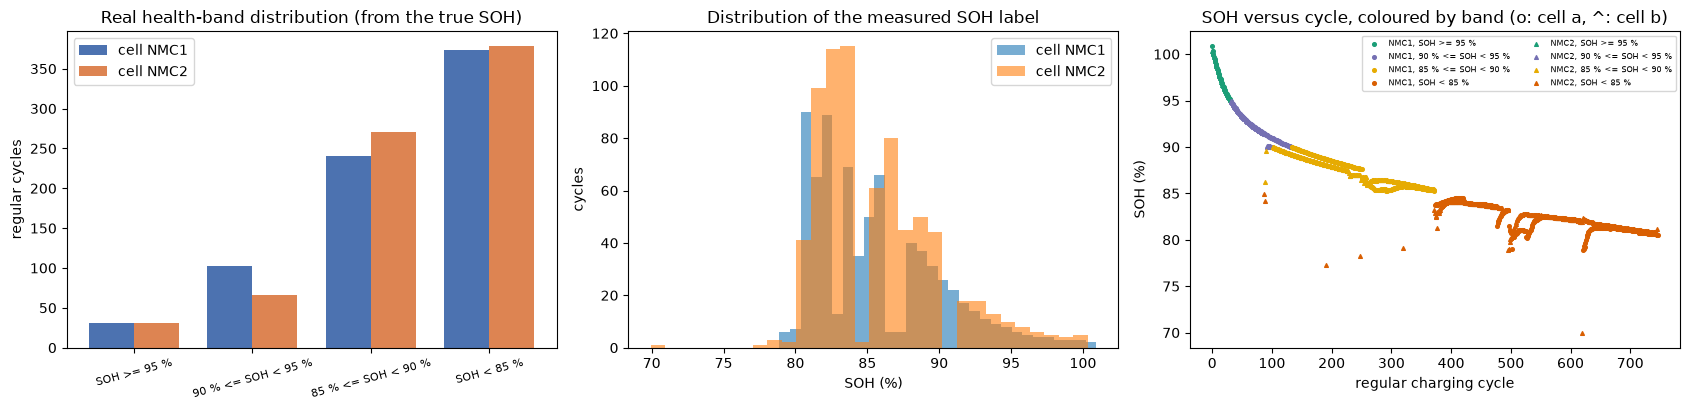

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
w = 0.38
for j, (c, r) in enumerate(cells.items()):
    ax[0].bar(np.arange(4) + (j - 0.5) * w, [(r.band == k).sum() for k in range(4)], w, label=f"cell {c}", color=["#4c72b0", "#dd8452"][j])
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(BANDS, rotation=15, fontsize=8); ax[0].set_ylabel("regular cycles"); ax[0].set_title("Real health-band distribution (from the true SOH)"); ax[0].legend()
for c, r in cells.items():
    ax[1].hist(r.soh * 100, bins=30, alpha=0.6, label=f"cell {c}")
ax[1].set_xlabel("SOH (%)"); ax[1].set_ylabel("cycles"); ax[1].set_title("Distribution of the measured SOH label"); ax[1].legend()
for c, r in cells.items():
    for k in range(4):
        m = r.band == k
        ax[2].scatter(r.cycle[m], r.soh[m] * 100, s=7, color=BAND_COLORS[k], marker="o" if c == "NMC1" else "^", label=f"{c}, {BANDS[k]}")
ax[2].set_xlabel("regular charging cycle"); ax[2].set_ylabel("SOH (%)"); ax[2].set_title("SOH versus cycle, coloured by band (o: cell a, ^: cell b)")
ax[2].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

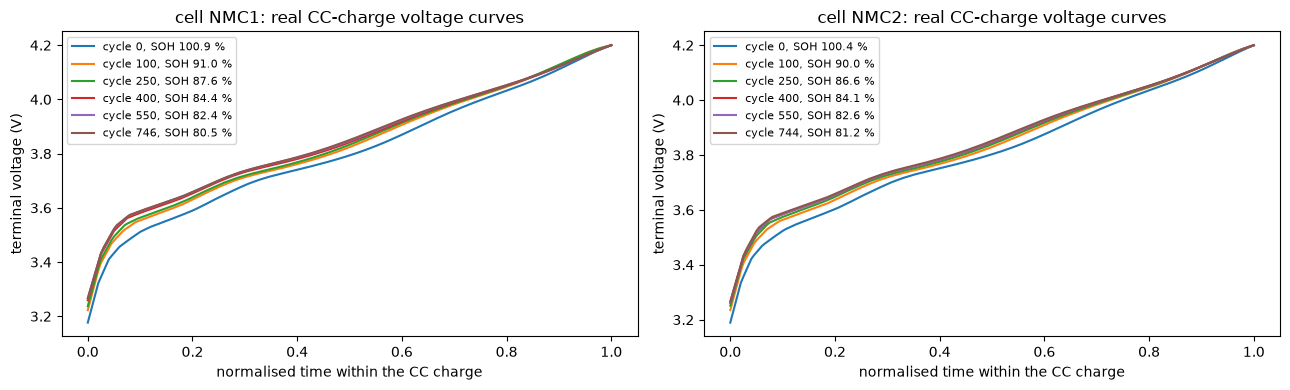

In [8]:
# raw measurements behind the features: constant-current charging voltage curves of real cycles at different health
curves = np.load(CURVE_NPZ)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, c in enumerate(("NMC1", "NMC2")):
    r = cells[c]; cur = curves[c]
    for target_cycle in (0, 100, 250, 400, 550, len(r) - 1):
        k = min(target_cycle, len(r) - 1)
        ax[j].plot(np.linspace(0, 1, cur.shape[1]), cur[k], label=f"cycle {k}, SOH {r.soh[k]*100:.1f} %")
    ax[j].set_xlabel("normalised time within the CC charge"); ax[j].set_ylabel("terminal voltage (V)"); ax[j].set_title(f"cell {c}: real CC-charge voltage curves"); ax[j].legend(fontsize=8)
plt.tight_layout(); plt.show()

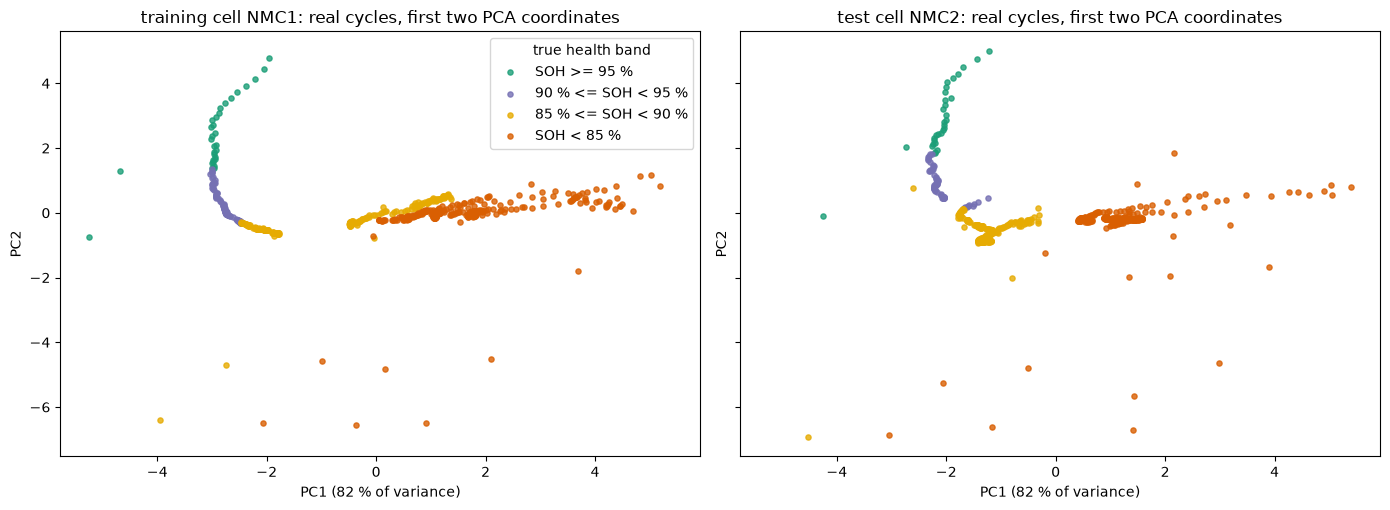

PCA fitted on the training cell only; explained variance ratio: [0.816 0.152]


In [9]:
# 2-D scatter of the real cycles coloured by their ground-truth health band; PCA fitted on the training cell (NMC1) only
sc_viz = StandardScaler().fit(cells["NMC1"][FEATS]); pca_viz = PCA(n_components=2, random_state=SEED).fit(sc_viz.transform(cells["NMC1"][FEATS]))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for j, c in enumerate(("NMC1", "NMC2")):
    Z = pca_viz.transform(sc_viz.transform(cells[c][FEATS]))
    for k in range(4):
        m = (cells[c].band == k).to_numpy()
        ax[j].scatter(Z[m, 0], Z[m, 1], s=14, color=BAND_COLORS[k], label=BANDS[k], alpha=0.8)
    ax[j].set_title(f"{'training' if c == 'NMC1' else 'test'} cell {c}: real cycles, first two PCA coordinates")
    ax[j].set_xlabel(f"PC1 ({pca_viz.explained_variance_ratio_[0]*100:.0f} % of variance)"); ax[j].set_ylabel("PC2")
ax[0].legend(title="true health band")
plt.tight_layout(); plt.show()
print("PCA fitted on the training cell only; explained variance ratio:", pca_viz.explained_variance_ratio_.round(3))

## Quantum Circuit Architecture

NOT_APPLICABLE: QBoost is an annealing / QUBO method, there is no gate-model quantum circuit; the optimisation problem is a QUBO matrix over 80 binary weights, drawn in Section 3.

## 3. QBoost: from a weighted ensemble of trees to a QUBO

**The weak regressors.** $N = 80$ decision trees $h_1 \dots h_N$ (Eq. 1). Their hyper-parameters (error criterion, maximum depth, minimum samples to split a node and to be a leaf) are chosen
once by grid-search cross-validation, as in Fig. 3 of the paper, on the fitting part of the training cell. Each tree is then trained on its own random 40 % subset of the
training cycles, so the trees differ ("the training set was split into subsets for training the DT weak classifiers").

**The loss as a QUBO.** With binary weights $w_i \in \{0,1\}$ the ensemble is $\hat y(x) = \frac1N \sum_i w_i h_i(x)$. The mean squared error over $m$ training cycles plus a
penalty $\lambda$ for every selected tree is

$$ L(w) = \frac1m \sum_{s=1}^{m}\Big(y_s - \frac1N\sum_i w_i h_i(x_s)\Big)^2 + \lambda \sum_i w_i
= \sum_{i,j} Q_{ij}\, w_i w_j + \text{const}, $$

$$ Q_{ii} = \frac{1}{mN^2}\sum_s h_i(x_s)^2 - \frac{2}{mN}\sum_s y_s h_i(x_s) + \lambda, \qquad Q_{ij} = \frac{2}{mN^2}\sum_s h_i(x_s)h_j(x_s)\;(i<j). $$

This is exactly the QBoost construction of Neven et al., a fully connected QUBO of 80 variables (the paper maps it onto the Advantage's Pegasus graph by minor embedding,
which needs more physical qubits than logical ones). The minimiser $w^\star$ is found by annealing; the final prediction is normalised by the number of selected trees,
$\hat y(x) = \sum_i w^\star_i h_i(x) / \sum_i w^\star_i$ ("normalizing boosted results", step F-H of Fig. 3). Without the penalty ($\lambda = 0$) the optimum keeps all 80 trees
(the paper reports "the optimal number of weak regressors was 80"); with $\lambda > 0$ the annealer decides which trees to drop, and $\lambda$ is picked on held-out training
cycles.

**The solver.** `SimulatedAnnealingSampler` from D-Wave's open-source `dwave-samplers` is a classical Metropolis annealer that accepts the same `BinaryQuadraticModel` a D-Wave
sampler accepts. It is not quantum annealing; the notebook therefore tests the QUBO formulation and the ensemble, **not** any quantum speed-up or quantum robustness.

In [10]:
def metrics(y, p):
    """Paper's four metrics on the SOH expressed in percent (so MAE and RMSE are in SOH points, R2 and MAPE in percent)."""
    y, p = 100 * np.asarray(y), 100 * np.asarray(p)
    return dict(R2=100 * r2_score(y, p), MAE=mean_absolute_error(y, p), MAPE=100 * mean_absolute_percentage_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5)

def fit_weak(X, y, params, seed, n_weak=N_WEAK, frac=SUBSET_FRAC):
    """n_weak decision trees, each trained on its own random subset of the training rows (CHOICE: subsets drawn without replacement)."""
    rng = np.random.default_rng(seed)
    trees, n = [], len(y)
    for _ in range(n_weak):
        idx = rng.choice(n, size=int(frac * n), replace=False)
        trees.append(DecisionTreeRegressor(**params, random_state=int(rng.integers(1 << 30))).fit(X[idx], y[idx]))
    return trees

def tree_matrix(trees, X):
    return np.column_stack([t.predict(X) for t in trees])          # H[s, i] = h_i(x_s)

def qubo_from_ensemble(H, y, lam):
    """Return the QUBO dictionary of L(w) above (H: m x N matrix of weak predictions, y: targets as fractions)."""
    m, N = H.shape
    G = H.T @ H / (m * N * N)
    lin = -2.0 * (H.T @ y) / (m * N) + lam
    Q = {}
    for i in range(N):
        Q[(i, i)] = float(G[i, i] + lin[i])
        for j in range(i + 1, N):
            Q[(i, j)] = float(2.0 * G[i, j])
    return Q

def anneal(Q, reads, sweeps, seed):
    """Simulated annealing on the QUBO; returns the best binary weight vector, its energy and all read energies."""
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q)
    ss = SimulatedAnnealingSampler().sample(bqm, num_reads=reads, num_sweeps=sweeps, seed=seed)
    n = max(max(k) for k in Q) + 1
    w = np.array([ss.first.sample[i] for i in range(n)], float)
    return w, float(ss.first.energy), ss.record.energy

def qboost_predict(trees, w, X):
    return tree_matrix(trees, X) @ w / max(w.sum(), 1.0)             # normalised boosted result

def energy(Q, w):
    return sum(v * w[i] * w[j] for (i, j), v in Q.items())

# optional real-annealer path (never executed here: needs `pip install dwave-system` and a Leap account)
def solve_with_leap(Q, token, num_reads=200):
    from dwave.system import DWaveSampler, EmbeddingComposite
    sampler = EmbeddingComposite(DWaveSampler(token=token))
    res = sampler.sample_qubo(Q, num_reads=num_reads)
    return res.first
if DWAVE_TOKEN:
    print("DWAVE_TOKEN set: use solve_with_leap(Q, DWAVE_TOKEN) on any QUBO below to try a real annealer.")
else:
    print("No D-Wave token: all QUBOs are solved with simulated annealing (dwave.samplers).")

No D-Wave token: all QUBOs are solved with simulated annealing (dwave.samplers).


### Does the annealer find the true optimum? An exact check on 16 trees

Eighty binary variables have $2^{80}$ states, so the notebook cannot enumerate them; but a 16-tree QUBO built from the same data has only 65,536. `dimod.ExactSolver` lists them all, which
tells us whether simulated annealing reaches the exact ground state. (This also validates the QUBO coefficients: the exact minimum must equal the loss of the best 0/1 weight vector evaluated directly.)

In [11]:
# 16-tree sub-problem from the training cell NMC1 (all five features)
Xa = cells["NMC1"][FEATS].to_numpy(float); ya = cells["NMC1"].soh.to_numpy(float)
trees16 = fit_weak(Xa, ya, dict(max_depth=5, min_samples_leaf=3), SEED, n_weak=16)
H16 = tree_matrix(trees16, Xa)
Q16 = qubo_from_ensemble(H16, ya, 5e-4)
t0 = time.time(); exact = dimod.ExactSolver().sample(dimod.BinaryQuadraticModel.from_qubo(Q16)); t_exact = time.time() - t0
w_ex = np.array([exact.first.sample[i] for i in range(16)], float)
w_sa, e_sa, _ = anneal(Q16, reads=READS, sweeps=SWEEPS, seed=SEED)
def direct_loss(H, y, w, lam):
    return float(np.mean((y - H @ w / H.shape[1]) ** 2) + lam * w.sum())
const = float(np.mean(ya ** 2))                                       # the constant dropped from the QUBO
print(f"exact ground-state energy      : {exact.first.energy:.8f}  ({int(w_ex.sum())} trees selected, {t_exact:.1f}s for 65,536 states)")
print(f"simulated-annealing energy     : {e_sa:.8f}  ({int(w_sa.sum())} trees selected)")
print(f"same selection as exact solver : {bool(np.array_equal(w_ex, w_sa))}")
print(f"QUBO energy + const == direct loss of the exact optimum: {np.isclose(exact.first.energy + const, direct_loss(H16, ya, w_ex, 5e-4))}")
assert np.isclose(exact.first.energy + const, direct_loss(H16, ya, w_ex, 5e-4)), "QUBO coefficients inconsistent with the loss"

exact ground-state energy      : -0.72886639  (16 trees selected, 0.9s for 65,536 states)
simulated-annealing energy     : -0.72886639  (16 trees selected)
same selection as exact solver : True
QUBO energy + const == direct loss of the exact optimum: True


## 4. Metrics, validation split and the Gaussian-random attack

**Metrics** are the paper's four: $R^2$ (in percent), MAE, MAPE and RMSE, computed on the SOH expressed in percent (so MAE and RMSE are in SOH points; MAPE in percent), which is the scale of Table I.

**Train and test.** One cell trains the models, the **other cell** is the test set (both directions are run: a -> b and b -> a). Inside the training cell every fifth block of 25 cycles is
held out as *validation* data; it chooses the tree hyper-parameters (cross-validation on the remaining blocks), the sparsity penalty $\lambda$ of the QUBO and the attack strength $\sigma$ below.
After that the models are re-fitted on the whole training cell. The test cell is used only for the final numbers.

**The attack.** The paper adds Gaussian random noise to the feature inputs (attack point 2 of Fig. 2) and does not say how much. We use
$x_{adv} = x + \sigma \cdot s_j \cdot \varepsilon,\ \varepsilon \sim \mathcal N(0,1)$ independently for every cycle and feature, with $s_j$ the training standard deviation of feature $j$.
The attack strength is the one unknown, so it is **calibrated on training-cell validation data only**: $\sigma$ is the value at which the random forest's validation $R^2$ under the attack falls to the
paper's attacked-RF value (81.68 %). This is an assumption made to put both models at the same attack level as the paper, not a result: the attacked-RF numbers are consequently *calibrated*, not independent.
The attacked QBoost numbers, and every comparison between QBoost and the random forest at that $\sigma$, are genuine outcomes. Section 8 shows the full curve over $\sigma$.

In [12]:
def block_split(n, block=BLOCK, every=VAL_EVERY):
    """CHOICE: contiguous blocks of `block` cycles; every `every`-th block is validation (so validation cycles sit between training cycles of all ages)."""
    blocks = np.arange(n) // block
    val = (blocks % every) == (every // 2)
    return blocks, val

def calibrate_sigma(model, X_val, y_val, sd, seed, target=PAPER_RF_ATTACK_R2, reps=4):
    """sigma at which the model's validation R2 under the Gaussian-random attack equals `target` (percent); noise draws are fixed by the seed."""
    rng = np.random.default_rng(seed + 1000)
    eps = [rng.standard_normal(X_val.shape) for _ in range(reps)]
    grid = np.arange(0.0, 3.001, 0.1)
    curve = np.array([np.mean([100 * r2_score(y_val, model.predict(X_val + s * sd * e)) for e in eps]) for s in grid])
    curve = np.minimum.accumulate(curve)                                    # enforce monotone decrease for the interpolation
    return float(np.interp(target, curve[::-1], grid[::-1]))

def tune_trees(X, y, groups, seed, grid=DT_GRID):
    """Grid-search CV of the tree hyper-parameters (criterion, depth, min samples split / leaf), GroupKFold on contiguous blocks."""
    gs = GridSearchCV(DecisionTreeRegressor(random_state=seed), grid, cv=GroupKFold(n_splits=5), scoring="neg_mean_squared_error")
    gs.fit(X, y, groups=groups)
    return gs.best_params_

print("block split of a 747-cycle cell:", {k: int(v) for k, v in zip(("train cycles", "validation cycles"), (np.sum(~block_split(747)[1]), np.sum(block_split(747)[1])))})

block split of a 747-cycle cell: {'train cycles': 597, 'validation cycles': 150}


## 5. The whole pipeline for one training cell, one seed, one feature set

`run_pipeline` follows Fig. 3 of the paper and the models of the comparison:

1. split the training cell into fitting and validation blocks (Section 4);
2. train the 80 weak trees on the fitting blocks; for every $\lambda$ in the grid build the QUBO, anneal it, and keep the $\lambda$ with the best validation $R^2$ of the normalised ensemble;
3. calibrate the attack strength $\sigma$ with a random forest fitted on the fitting blocks (Section 4);
4. **re-fit everything on the whole training cell** with the chosen settings: random forest (80 trees, same tuned tree hyper-parameters), single tuned decision tree, the 80 subset trees
   with all weights equal to one (*Bag-80*: bagging without annealing, to show what the QUBO selection adds), and QBoost (the 80 subset trees with the annealed weights);
5. evaluate every model on the test cell with normal data, with the attack at the calibrated $\sigma$ (mean over `NOISE_REPS` noise draws), and over a grid of attack strengths.

In [13]:
def run_pipeline(train, test, feats, seed, params, keep=False):
    Xtr, ytr = train[feats].to_numpy(float), train.soh.to_numpy(float)
    Xte, yte = test[feats].to_numpy(float), test.soh.to_numpy(float)
    sd = Xtr.std(0)                                                         # training-cell feature scale for the attack noise
    blocks, val = block_split(len(train)); fit = ~val
    tree_kw = {k: v for k, v in params.items() if k != "criterion"}
    # --- steps 1-2: weak trees on the fitting blocks, lambda chosen on the validation blocks
    t0 = time.perf_counter()
    trees = fit_weak(Xtr[fit], ytr[fit], params, seed)
    Hf = tree_matrix(trees, Xtr[fit])
    best, lam_curve = None, []
    for lam in LAM_GRID:
        w, e, _ = anneal(qubo_from_ensemble(Hf, ytr[fit], lam), READS, SWEEPS, seed)
        if w.sum() == 0:
            continue
        r2v = r2_score(ytr[val], qboost_predict(trees, w, Xtr[val]))
        lam_curve.append((lam, int(w.sum()), 100 * r2v))
        if best is None or r2v > best[0]:
            best = (r2v, lam, int(w.sum()))
    val_r2_qb, lam, k_val = best
    # --- step 3: attack strength from the random forest's validation behaviour
    rf_fit = RandomForestRegressor(n_estimators=N_WEAK, random_state=seed, **params).fit(Xtr[fit], ytr[fit])
    sigma = calibrate_sigma(rf_fit, Xtr[val], ytr[val], sd, seed)
    # --- step 4: re-fit on the whole training cell
    trees = fit_weak(Xtr, ytr, params, seed)
    H = tree_matrix(trees, Xtr)
    Q = qubo_from_ensemble(H, ytr, lam)
    t1 = time.perf_counter(); w, e_best, e_reads = anneal(Q, READS, SWEEPS, seed); t_anneal = time.perf_counter() - t1
    t_qboost = time.perf_counter() - t0
    t1 = time.perf_counter(); rf = RandomForestRegressor(n_estimators=N_WEAK, random_state=seed, **params).fit(Xtr, ytr); t_rf = time.perf_counter() - t1
    dt = DecisionTreeRegressor(random_state=seed, **params).fit(Xtr, ytr)
    def predict_all(X):
        """Predictions of the four models on X (the 80 trees are evaluated once and shared by QBoost and Bag-80)."""
        Hx = tree_matrix(trees, X)
        return {"RF": rf.predict(X), "QBoost": Hx @ w / max(w.sum(), 1.0), "Bag-80": Hx.mean(axis=1), "DT": dt.predict(X)}
    # --- step 5: evaluation
    rng = np.random.default_rng(seed + 2000)
    eps = [rng.standard_normal(Xte.shape) for _ in range(NOISE_REPS)]
    res, sweep = {}, {name: [] for name in ("RF", "QBoost", "Bag-80", "DT")}
    p0 = predict_all(Xte)
    ms = [{n: metrics(yte, p) for n, p in predict_all(Xte + sigma * sd * e).items()} for e in eps]
    late = test.cycle.to_numpy() >= 400                                      # paper: larger errors "after 400 cycles"
    for name in p0:
        res[(name, "normal")] = metrics(yte, p0[name])
        res[(name, "attack")] = {k: float(np.mean([m[name][k] for m in ms])) for k in ms[0][name]}
        res[(name, "normal")]["MAE_early"] = float(100 * np.mean(np.abs(yte[~late] - p0[name][~late])))
        res[(name, "normal")]["MAE_late"] = float(100 * np.mean(np.abs(yte[late] - p0[name][late]))) if late.any() else np.nan
    for s in SIGMA_SWEEP:
        sw = [{n: metrics(yte, p)["R2"] for n, p in predict_all(Xte + s * sd * e).items()} for e in eps[:max(3, NOISE_REPS // 4)]]
        for name in sweep:
            sweep[name].append((s, float(np.mean([d[name] for d in sw]))))
    out = dict(res=res, sweep=sweep, sigma=sigma, lam=lam, k=int(w.sum()), k_val=k_val, val_r2_qb=val_r2_qb, lam_curve=lam_curve,
               t_anneal=t_anneal, t_qboost=t_qboost, t_rf=t_rf, e_best=e_best, params=params)
    if keep:
        pa = predict_all(Xtr)
        out.update(Q=Q, e_reads=e_reads, w=w, y_train=ytr, y_test=yte, sd=sd, pred_train=pa["QBoost"], pred_train_rf=pa["RF"],
                   pred_test=p0, pred_attack=predict_all(Xte + sigma * sd * eps[0]), val_mask=val)
    return out

## 6. Running both directions over all seeds

For each direction (train on cell *a* and test on *b*, and the reverse) the tree hyper-parameters are tuned once (grid-search CV on the fitting blocks, seed 42); then `run_pipeline` is
repeated for every seed. The seed changes the tree subsets, the annealing and the noise draws. One run at `FAST_MODE = False` takes between about one and several minutes depending on how busy the CPU is (the recorded full run, 20 runs plus the ablation, took about 75 minutes on a heavily shared machine; `FAST_MODE = True` takes a few minutes). The headline numbers are means over both
directions and all seeds.

In [14]:
DIRECTIONS = [("NMC1", "NMC2"), ("NMC2", "NMC1")]
tuned = {}
for a, b in DIRECTIONS:
    tr = cells[a]; blocks, val = block_split(len(tr))
    tuned[(a, b, "all5")] = tune_trees(tr[FEATS].to_numpy(float)[~val], tr.soh.to_numpy(float)[~val], blocks[~val], SEED)
    print(f"{a} -> {b}: tuned tree hyper-parameters {tuned[(a, b, 'all5')]}")

runs, t_all = [], time.time()
for a, b in DIRECTIONS:
    for seed in SEEDS:
        keep = (a, b, seed) == ("NMC1", "NMC2", SEEDS[0])
        r = run_pipeline(cells[a], cells[b], FEATS, seed, tuned[(a, b, "all5")], keep=keep)
        r.update(train=a, test=b, seed=seed, feats="all5"); runs.append(r)
        print(f"  {a}->{b} seed {seed}: sigma={r['sigma']:.2f}  lambda={r['lam']:g}  selected trees={r['k']:2d}  "
              f"R2 normal RF {r['res'][('RF','normal')]['R2']:.2f} / QBoost {r['res'][('QBoost','normal')]['R2']:.2f}  "
              f"attack RF {r['res'][('RF','attack')]['R2']:.2f} / QBoost {r['res'][('QBoost','attack')]['R2']:.2f}  ({time.time()-t_all:.0f}s)", flush=True)
keep_run = [r for r in runs if "Q" in r][0]

NMC1 -> NMC2: tuned tree hyper-parameters {'criterion': 'absolute_error', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


NMC2 -> NMC1: tuned tree hyper-parameters {'criterion': 'absolute_error', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


  NMC1->NMC2 seed 42: sigma=0.42  lambda=0.006  selected trees=54  R2 normal RF 98.58 / QBoost 98.38  attack RF 81.62 / QBoost 82.02  (155s)


  NMC1->NMC2 seed 43: sigma=0.43  lambda=0.003  selected trees=67  R2 normal RF 98.22 / QBoost 98.29  attack RF 81.43 / QBoost 82.69  (303s)


  NMC1->NMC2 seed 44: sigma=0.41  lambda=0.015  selected trees=15  R2 normal RF 98.52 / QBoost 97.81  attack RF 82.28 / QBoost 83.31  (440s)


...

  NMC2->NMC1 seed 47: sigma=0.43  lambda=0  selected trees=80  R2 normal RF 99.13 / QBoost 99.16  attack RF 86.94 / QBoost 87.95  (2463s)


  NMC2->NMC1 seed 48: sigma=0.43  lambda=0  selected trees=80  R2 normal RF 99.13 / QBoost 98.87  attack RF 86.99 / QBoost 87.36  (2591s)


  NMC2->NMC1 seed 49: sigma=0.39  lambda=0  selected trees=80  R2 normal RF 99.12 / QBoost 98.73  attack RF 89.37 / QBoost 89.40  (2728s)


  NMC2->NMC1 seed 50: sigma=0.39  lambda=0.001  selected trees=76  R2 normal RF 98.94 / QBoost 99.03  attack RF 88.70 / QBoost 89.49  (2840s)


  NMC2->NMC1 seed 51: sigma=0.40  lambda=0.01  selected trees=37  R2 normal RF 98.89 / QBoost 98.74  attack RF 88.07 / QBoost 89.15  (2999s)


## 7. The QUBO, the annealing energies and the selected trees

For the first seed of the a -> b direction: the 80 x 80 QUBO matrix (diagonal = per-tree terms, off-diagonal = interaction between two trees), the energies of the annealing reads, and which trees the
annealer kept. With the validation-chosen $\lambda$ the optimum keeps most trees, as in the paper's "optimal number was 80".

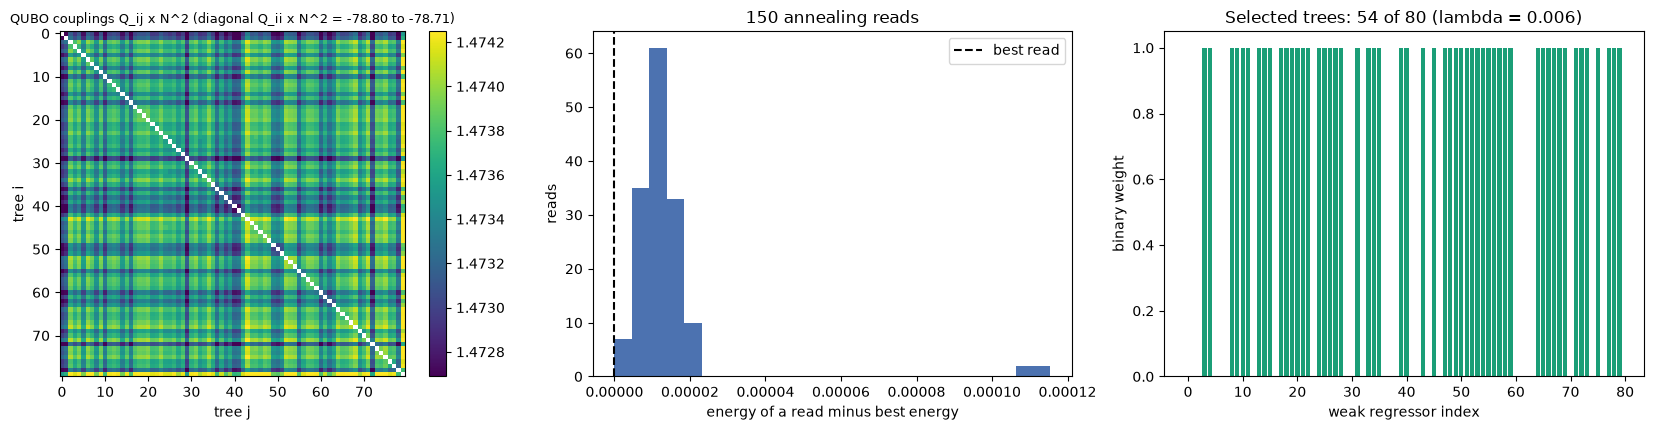

best simulated-annealing energy -0.3350306221   |   tabu-search energy on the same QUBO -0.3350516864   (difference +2.11e-05; negative or zero means annealing is at least as good)


,mean_selected_trees,mean_val_R2,std_val_R2,times chosen
lam,,,,
0.000,80.00,99.586,0.123,4
0.001,76.00,99.587,0.128,2
0.003,67.00,99.564,0.118,2
0.006,54.00,99.552,0.140,5
0.010,36.95,99.508,0.200,4
0.015,15.00,99.370,0.326,3


In [15]:
Qm = np.full((N_WEAK, N_WEAK), np.nan); diag = np.zeros(N_WEAK)
for (i, j), v in keep_run["Q"].items():
    if i == j:
        diag[i] = v
    else:
        Qm[i, j] = Qm[j, i] = v                                         # the coupling of the pair (i, j), shown symmetrically
off = Qm[~np.isnan(Qm)] * N_WEAK ** 2
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
im = ax[0].imshow(Qm * N_WEAK ** 2, cmap="viridis", vmin=np.percentile(off, 1), vmax=np.percentile(off, 99))
ax[0].set_title(f"QUBO couplings Q_ij x N^2 (diagonal Q_ii x N^2 = {diag.min()*N_WEAK**2:.2f} to {diag.max()*N_WEAK**2:.2f})", fontsize=9)
ax[0].set_xlabel("tree j"); ax[0].set_ylabel("tree i"); plt.colorbar(im, ax=ax[0])
ax[1].hist(keep_run["e_reads"] - keep_run["e_best"], bins=25, color="#4c72b0")
ax[1].axvline(0, color="k", ls="--", label="best read"); ax[1].set_xlabel("energy of a read minus best energy"); ax[1].set_ylabel("reads"); ax[1].set_title(f"{READS} annealing reads"); ax[1].legend()
ax[2].bar(range(N_WEAK), keep_run["w"], color=["#1b9e77" if x else "#bbbbbb" for x in keep_run["w"]])
ax[2].set_xlabel("weak regressor index"); ax[2].set_ylabel("binary weight"); ax[2].set_title(f"Selected trees: {keep_run['k']} of {N_WEAK} (lambda = {keep_run['lam']:g})")
plt.tight_layout(); plt.show()
Qd = {k: v for k, v in keep_run["Q"].items()}
tabu = TabuSampler().sample(dimod.BinaryQuadraticModel.from_qubo(Qd), num_reads=20, seed=SEED)
print(f"best simulated-annealing energy {keep_run['e_best']:.10f}   |   tabu-search energy on the same QUBO {tabu.first.energy:.10f}   "
      f"(difference {keep_run['e_best'] - tabu.first.energy:+.2e}; negative or zero means annealing is at least as good)")
# how much does the number of selected trees matter? validation R2 of the annealed ensemble for every lambda (fitting blocks only), all runs
lc = pd.DataFrame([dict(lam=l, selected_trees=k, val_R2=v) for r in runs for (l, k, v) in r["lam_curve"]])
chosen = pd.Series([r["lam"] for r in runs]).value_counts().rename("times chosen")
display(lc.groupby("lam").agg(mean_selected_trees=("selected_trees", "mean"), mean_val_R2=("val_R2", "mean"), std_val_R2=("val_R2", "std")).join(chosen).fillna(0).round(3))

## 8. Table I re-computed, and the paper's Figures 4 and 5

First the table: for every model, normal and attacked, the four metrics as mean $\pm$ standard deviation over all runs (both directions, all seeds). The models are the paper's two
(RF and QBoost) plus two classical references on the identical five features: a single tuned decision tree and Bag-80 (the same 80 subset trees with all weights equal to 1, i.e. QBoost without the annealed selection).

In [16]:
def collect(runs_, models=("RF", "QBoost", "Bag-80", "DT")):
    rows = []
    for m in models:
        for cond in ("normal", "attack"):
            for metric in ("R2", "MAE", "MAPE", "RMSE"):
                v = np.array([r["res"][(m, cond)][metric] for r in runs_])
                rows.append(dict(model=m, condition=cond, metric=metric, mean=v.mean(), std=v.std(ddof=1) if len(v) > 1 else 0.0, n_runs=len(v)))
    return pd.DataFrame(rows)
tab = collect(runs)
show = tab.assign(value=lambda d: d["mean"].map("{:.3f}".format) + " +- " + d["std"].map("{:.3f}".format)).pivot_table(index=["model", "metric"], columns="condition", values="value", aggfunc="first")
display(show.reindex(["R2", "MAE", "MAPE", "RMSE"], level=1).reindex(["RF", "QBoost", "Bag-80", "DT"], level=0))
sig = np.array([r["sigma"] for r in runs]); ks = np.array([r["k"] for r in runs]); lams = [r["lam"] for r in runs]
print(f"calibrated attack strength sigma: mean {sig.mean():.2f} (min {sig.min():.2f}, max {sig.max():.2f}) feature standard deviations")
print(f"trees selected by the annealed QUBO: mean {ks.mean():.1f} of {N_WEAK} (min {ks.min()}, max {ks.max()}); lambda values chosen: {sorted(set(lams))}")
print(f"mean training time: random forest {np.mean([r['t_rf'] for r in runs]):.2f} s | QBoost (trees + all lambda annealings + final annealing) {np.mean([r['t_qboost'] for r in runs]):.1f} s, of which the final annealing {np.mean([r['t_anneal'] for r in runs]):.2f} s")

condition               attack           normal
model  metric                                  
RF     R2      85.116 +- 2.856  98.788 +- 0.322
       MAE      1.321 +- 0.099   0.256 +- 0.021
       MAPE     1.546 +- 0.118   0.288 +- 0.027
       RMSE     1.670 +- 0.124   0.474 +- 0.053
QBoost R2      85.943 +- 2.853  98.570 +- 0.469
       MAE      1.275 +- 0.106   0.288 +- 0.037
       MAPE     1.492 +- 0.128   0.325 +- 0.043
       RMSE     1.622 +- 0.129   0.513 +- 0.072
Bag-80 R2      85.968 +- 2.794  98.594 +- 0.394
       MAE      1.274 +- 0.103   0.284 +- 0.021
       MAPE     1.491 +- 0.125   0.320 +- 0.026
       RMSE     1.621 +- 0.127   0.510 +- 0.062
DT     R2      82.875 +- 3.034  98.015 +- 0.893
       MAE      1.419 +- 0.092   0.282 +- 0.064
       MAPE     1.658 +- 0.108   0.317 +- 0.072
       RMSE     1.793 +- 0.121   0.595 +- 0.141

calibrated attack strength sigma: mean 0.41 (min 0.38, max 0.43) feature standard deviations
trees selected by the annealed QUBO: mean 53.5 of 80 (min 15, max 80); lambda values chosen: [0.0, 0.001, 0.003, 0.006, 0.01, 0.015]
mean training time: random forest 5.69 s | QBoost (trees + all lambda annealings + final annealing) 100.5 s, of which the final annealing 10.23 s


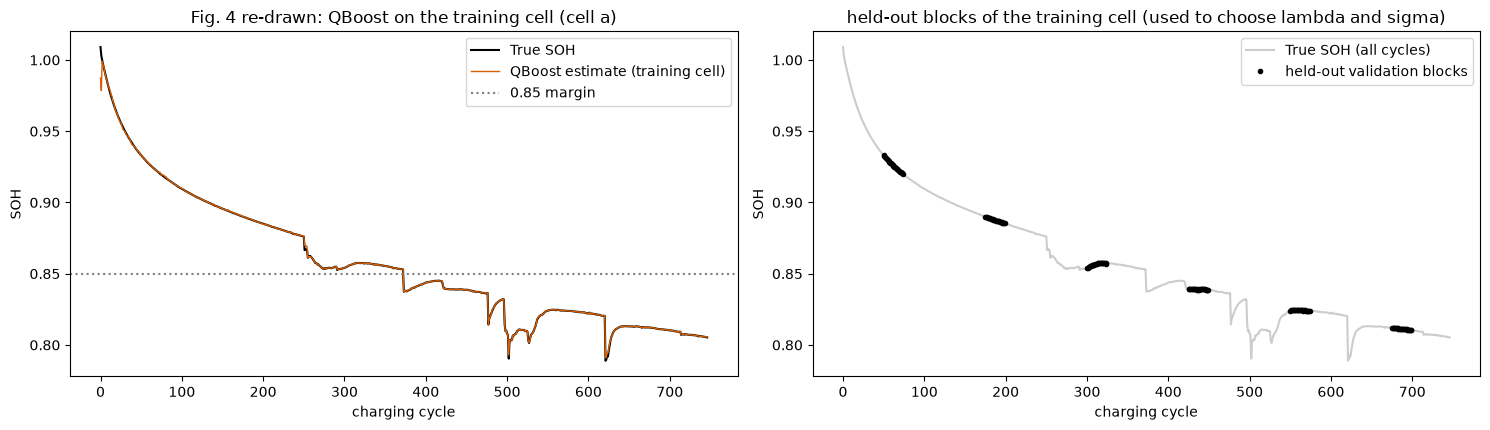

In [17]:
# Fig. 4 of the paper: training result of QBoost (cell NMC1 as the training cell, first seed)
r0 = keep_run
cyc_tr = cells["NMC1"].cycle.to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].plot(cyc_tr, r0["y_train"], "k", label="True SOH"); ax[0].plot(cyc_tr, r0["pred_train"], color="#d95f02", lw=1, label="QBoost estimate (training cell)")
ax[0].axhline(0.85, color="grey", ls=":", label="0.85 margin")
ax[0].set_xlabel("charging cycle"); ax[0].set_ylabel("SOH"); ax[0].set_title("Fig. 4 re-drawn: QBoost on the training cell (cell a)"); ax[0].legend()
vm = r0["val_mask"]
ax[1].plot(cyc_tr, r0["y_train"], color="#cccccc", label="True SOH (all cycles)")
ax[1].plot(cyc_tr[vm], r0["y_train"][vm], "k.", label="held-out validation blocks")
ax[1].set_xlabel("charging cycle"); ax[1].set_ylabel("SOH"); ax[1].set_title("held-out blocks of the training cell (used to choose lambda and sigma)")
ax[1].legend(); plt.tight_layout(); plt.show()

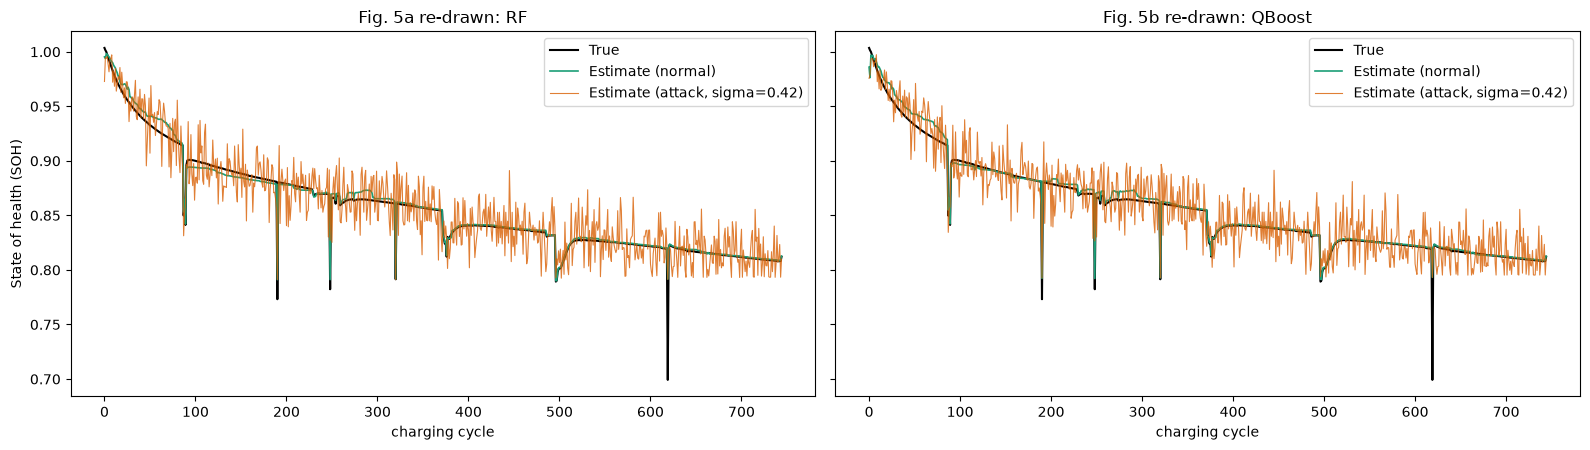

this run, attacked test cell: RF R2 81.62, QBoost R2 82.02


In [18]:
# Fig. 5 of the paper: SOH estimates on the test cell (NMC2), without and with the attack, (a) RF and (b) QBoost; first seed, a -> b
cyc_te = cells["NMC2"].cycle.to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
for j, name in enumerate(("RF", "QBoost")):
    ax[j].plot(cyc_te, keep_run["y_test"], "k", label="True")
    ax[j].plot(cyc_te, keep_run["pred_test"][name], color="#1b9e77", lw=1.2, label="Estimate (normal)")
    ax[j].plot(cyc_te, keep_run["pred_attack"][name], color="#d95f02", lw=0.8, alpha=0.8, label=f"Estimate (attack, sigma={keep_run['sigma']:.2f})")
    ax[j].set_xlabel("charging cycle"); ax[j].set_title(f"Fig. 5{'ab'[j]} re-drawn: {name}"); ax[j].legend()
ax[0].set_ylabel("State of health (SOH)")
plt.tight_layout(); plt.show()
m_rf, m_qb = keep_run["res"][("RF", "attack")], keep_run["res"][("QBoost", "attack")]
print(f"this run, attacked test cell: RF R2 {m_rf['R2']:.2f}, QBoost R2 {m_qb['R2']:.2f}")

## 9. Robustness over all attack strengths

The paper tests one attack level. Because the attack strength is the unknown of this reproduction, the figure below shows the test $R^2$ of every model as the noise grows from 0 to 2 training
standard deviations per feature (mean over both directions and all seeds, bands $\pm$ one standard deviation across runs). The vertical line marks the mean calibrated $\sigma$ of Section 4.
Where QBoost's curve is above the random forest's, QBoost is the more robust model at that attack strength.

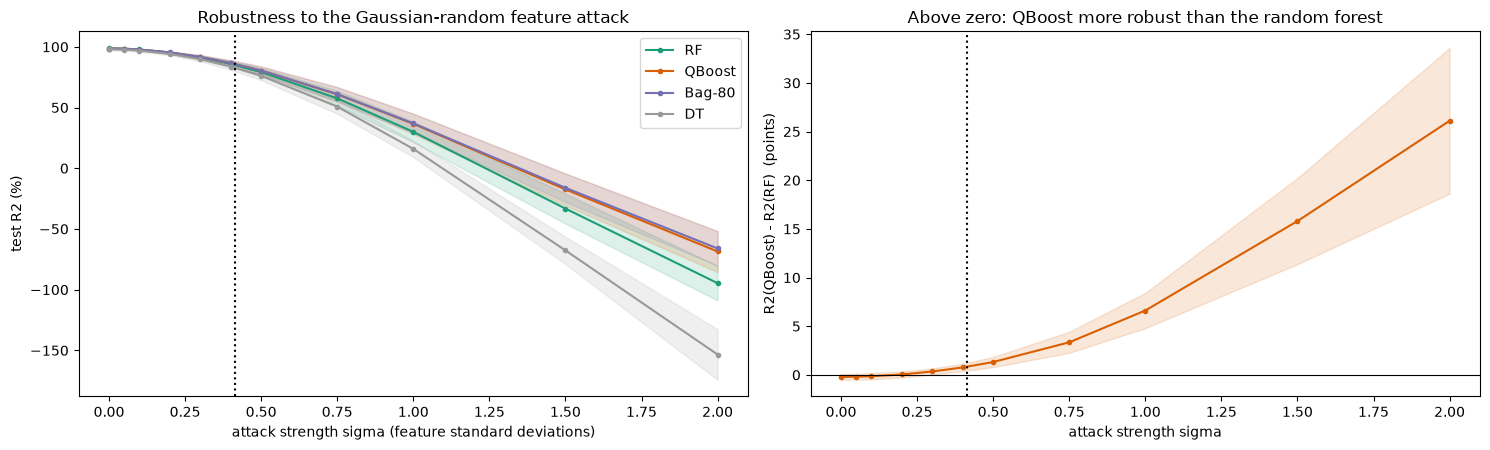

 sigma     RF  QBoost  Bag-80      DT  QBoost-RF
  0.00  98.79   98.57   98.59   98.01      -0.22
  0.05  98.55   98.36   98.39   97.69      -0.19
  0.10  97.84   97.70   97.74   96.89      -0.14
  0.20  95.27   95.31   95.35   94.16       0.04
  0.30  91.25   91.60   91.62   89.78       0.35
  0.40  85.85   86.62   86.63   83.76       0.77
  0.50  79.16   80.48   80.51   76.15       1.32
  0.75  57.57   60.92   61.04   50.74       3.35
  1.00  30.00   36.61   37.00   15.98       6.61
  1.50 -33.21  -17.42  -16.11  -67.64      15.80
  2.00 -94.65  -68.54  -66.07 -153.41      26.11


In [19]:
sig_grid = np.array(SIGMA_SWEEP)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
curves_all = {}
for name, col in zip(("RF", "QBoost", "Bag-80", "DT"), ("#1b9e77", "#d95f02", "#7570b3", "#999999")):
    arr = np.array([[v for _, v in r["sweep"][name]] for r in runs])
    curves_all[name] = arr
    ax[0].plot(sig_grid, arr.mean(0), "-o", ms=3, color=col, label=name)
    ax[0].fill_between(sig_grid, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.15)
ax[0].axvline(sig.mean(), color="k", ls=":"); ax[0].set_xlabel("attack strength sigma (feature standard deviations)"); ax[0].set_ylabel("test R2 (%)"); ax[0].set_title("Robustness to the Gaussian-random feature attack"); ax[0].legend()
diff = curves_all["QBoost"] - curves_all["RF"]
ax[1].plot(sig_grid, diff.mean(0), "-o", ms=3, color="#d95f02"); ax[1].fill_between(sig_grid, diff.mean(0) - diff.std(0), diff.mean(0) + diff.std(0), color="#d95f02", alpha=0.15)
ax[1].axhline(0, color="k", lw=0.8); ax[1].axvline(sig.mean(), color="k", ls=":"); ax[1].set_xlabel("attack strength sigma"); ax[1].set_ylabel("R2(QBoost) - R2(RF)  (points)"); ax[1].set_title("Above zero: QBoost more robust than the random forest")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"sigma": sig_grid, "RF": curves_all["RF"].mean(0).round(2), "QBoost": curves_all["QBoost"].mean(0).round(2),
                    "Bag-80": curves_all["Bag-80"].mean(0).round(2), "DT": curves_all["DT"].mean(0).round(2), "QBoost-RF": diff.mean(0).round(2)}).to_string(index=False))

## 10. Ablation: the same experiment without the discharge-capacity feature

The label is the discharge capacity of the same cycle divided by a constant, so `discharge_capacity` is almost a copy of the answer (see the critical reading). To see how the two models behave when the
estimator must infer the SOH from the other four features (recovery voltage, entropy, kurtosis, skewness), the whole procedure (hyper-parameter tuning, $\lambda$, calibrated $\sigma$, both directions) is repeated
without it, for a few seeds. This is **an addition of this notebook**, not a paper experiment.

In [20]:
FEATS4 = [f for f in FEATS if f != "discharge_capacity"]
abl_runs, t_abl = [], time.time()
for a, b in DIRECTIONS:
    tr = cells[a]; blocks, val = block_split(len(tr))
    p4 = tune_trees(tr[FEATS4].to_numpy(float)[~val], tr.soh.to_numpy(float)[~val], blocks[~val], SEED)
    for seed in ABL_SEEDS:
        r = run_pipeline(cells[a], cells[b], FEATS4, seed, p4); r.update(train=a, test=b, seed=seed, feats="no_Qd"); abl_runs.append(r)
        print(f"  {a}->{b} seed {seed}: sigma={r['sigma']:.2f} selected={r['k']:2d}  R2 normal RF {r['res'][('RF','normal')]['R2']:.2f} / QBoost {r['res'][('QBoost','normal')]['R2']:.2f}  "
              f"attack RF {r['res'][('RF','attack')]['R2']:.2f} / QBoost {r['res'][('QBoost','attack')]['R2']:.2f} ({time.time()-t_abl:.0f}s)", flush=True)
tab4 = collect(abl_runs, models=("RF", "QBoost", "Bag-80"))
display(tab4.assign(value=lambda d: d["mean"].map("{:.3f}".format) + " +- " + d["std"].map("{:.3f}".format)).pivot_table(index=["model", "metric"], columns="condition", values="value", aggfunc="first").reindex(["R2", "MAE", "MAPE", "RMSE"], level=1).reindex(["RF", "QBoost", "Bag-80"], level=0))

  NMC1->NMC2 seed 42: sigma=0.34 selected=54  R2 normal RF 87.37 / QBoost 89.05  attack RF 78.49 / QBoost 76.28 (182s)


  NMC1->NMC2 seed 43: sigma=0.30 selected=76  R2 normal RF 86.90 / QBoost 88.19  attack RF 80.62 / QBoost 77.33 (296s)


  NMC1->NMC2 seed 44: sigma=0.32 selected=54  R2 normal RF 88.41 / QBoost 87.96  attack RF 80.26 / QBoost 78.00 (492s)


  NMC2->NMC1 seed 42: sigma=0.26 selected=76  R2 normal RF 89.85 / QBoost 91.28  attack RF 87.13 / QBoost 87.40 (687s)


  NMC2->NMC1 seed 43: sigma=0.20 selected=37  R2 normal RF 88.84 / QBoost 91.58  attack RF 87.57 / QBoost 89.32 (849s)


  NMC2->NMC1 seed 44: sigma=0.19 selected=80  R2 normal RF 89.30 / QBoost 91.22  attack RF 88.21 / QBoost 89.52 (1069s)


condition               attack           normal
model  metric                                  
RF     R2      83.714 +- 4.373  88.446 +- 1.134
       MAE      1.366 +- 0.076   1.110 +- 0.168
       MAPE     1.588 +- 0.083   1.279 +- 0.212
       RMSE     1.740 +- 0.192   1.479 +- 0.043
QBoost R2      82.974 +- 6.387  89.881 +- 1.664
       MAE      1.345 +- 0.150   0.985 +- 0.145
       MAPE     1.562 +- 0.168   1.137 +- 0.181
       RMSE     1.763 +- 0.297   1.380 +- 0.078
Bag-80 R2      82.526 +- 6.744  90.024 +- 1.383
       MAE      1.362 +- 0.160   0.982 +- 0.166
       MAPE     1.582 +- 0.181   1.134 +- 0.203
       RMSE     1.784 +- 0.311   1.372 +- 0.062

**Reading the ablation (numbers of the run recorded above).** Without `discharge_capacity` the problem is clearly harder: on normal data both models fall from about 98.6-98.8 % to about 88-90 % $R^2$ (MAE about 1 SOH point instead of 0.26-0.29), and
the calibrated attack strength shrinks to $\sigma \approx 0.2$-0.35 because the remaining features are much more fragile. QBoost is slightly ahead of the random forest on normal data (about 89.9 % against 88.4 %) and
slightly behind under attack (about 83.0 % against 83.7 %); with only three seeds and two directions these differences are well inside the run-to-run spread (the standard deviations are 1-6 points), so no ordering can be claimed.

## 11. Paper versus this notebook

**Numeric claims (Table I).** One row per number. The verdict is **reproduced** when our mean is within 2 points of the paper's $R^2$, or within 0.02 of the paper's MAE / MAPE / RMSE
(the paper reports two or three decimals, so 0.02 is a strict band); **exceeded** when our value is better than the paper's by more than the band (higher $R^2$, lower error), **not reached** when it is worse.
The rows for the attacked random forest are marked *calibrated*: the attack strength was set so that the RF's validation $R^2$ meets the paper's 81.68 %, so agreement there is by construction.

**Qualitative claims** are tested by the sign of the mean per-run difference in $R^2$: the paper's direction is *reproduced* when the mean difference exceeds two standard errors of the per-run differences, a *tie* when it is within two standard errors of zero, *reversed* when it is more than two standard errors the other way. The claim about the quantum annealer itself (anything that requires real quantum hardware) **cannot be checked** because the QUBO
is solved by simulated annealing.

In [21]:
PAPER = {("RF", "normal"): dict(R2=98.59, MAE=0.408, MAPE=0.487, RMSE=0.574), ("QBoost", "normal"): dict(R2=91.30, MAE=0.951, MAPE=1.163, RMSE=1.422),
         ("RF", "attack"): dict(R2=81.68, MAE=1.717, MAPE=2.036, RMSE=2.068), ("QBoost", "attack"): dict(R2=84.99, MAE=1.362, MAPE=1.596, RMSE=1.885)}
rows = []
for (model, cond), vals in PAPER.items():
    for metric, pv in vals.items():
        x = tab[(tab.model == model) & (tab.condition == cond) & (tab.metric == metric)].iloc[0]
        tol = 2.0 if metric == "R2" else 0.02
        gap = x["mean"] - pv
        better = gap > 0 if metric == "R2" else gap < 0
        verdict = "reproduced" if abs(gap) <= tol else ("exceeded" if better else "not reached")
        rows.append(dict(claim=f"Table I: {metric}, {model}, {cond}", paper=pv, notebook=f"{x['mean']:.3f} +- {x['std']:.3f}", gap=round(gap, 3), tolerance=tol, verdict=verdict,
                         note="calibrated" if (model == "RF" and cond == "attack" and metric == "R2") else ""))
def mean_of(model, cond, metric):
    return tab[(tab.model == model) & (tab.condition == cond) & (tab.metric == metric)]["mean"].iloc[0]
def sign_claim(text, paper_text, per_run_diff):
    """Paired test over runs: the paper's direction counts as reproduced when the mean difference is positive and larger than twice its standard error
    (runs are treated as independent, which flatters the evidence); within two standard errors of zero it is a tie; otherwise it is reversed."""
    d = np.asarray(per_run_diff, float); m = d.mean(); sem = d.std(ddof=1) / np.sqrt(len(d))
    v = "reproduced" if m > 2 * sem else ("reversed" if m < -2 * sem else "tie (not distinguishable)")
    rows.append(dict(claim=text, paper=paper_text, notebook=f"{m:+.2f} +- {sem:.2f} (SEM)", gap="", tolerance="2 SEM", verdict=v, note=""))
def per_run(model, cond, metric="R2"):
    return np.array([r["res"][(model, cond)][metric] for r in runs])
sign_claim("RF more accurate than QBoost on normal test data (R2_RF - R2_QBoost)", "+7.29", per_run("RF", "normal") - per_run("QBoost", "normal"))
sign_claim("QBoost more robust than RF under attack (R2_QBoost - R2_RF)", "+3.31", per_run("QBoost", "attack") - per_run("RF", "attack"))
sign_claim("RF loses more R2 than QBoost under attack (drop_RF - drop_QBoost)", "+10.6",
           (per_run("RF", "normal") - per_run("RF", "attack")) - (per_run("QBoost", "normal") - per_run("QBoost", "attack")))
rows.append(dict(claim="optimal number of weak regressors is 80 (selected trees, mean)", paper="80", notebook=f"{ks.mean():.1f} (min {ks.min()}, max {ks.max()})", gap="", tolerance="",
                 verdict="reproduced" if ks.mean() >= 78 else "not reached", note="with lambda chosen on validation; lambda = 0 keeps all 80"))
late = np.array([r["res"][("QBoost", "normal")]["MAE_late"] for r in runs]); early = np.array([r["res"][("QBoost", "normal")]["MAE_early"] for r in runs])
rows.append(dict(claim="QBoost errors larger at low SOH (cycles >= 400) than earlier, normal data (MAE late / early)", paper="larger", notebook=f"{np.nanmean(late):.2f} / {np.nanmean(early):.2f}", gap="", tolerance="",
                 verdict="reproduced" if np.nanmean(late) > 1.1 * np.nanmean(early) else "not reached", note=""))
rows.append(dict(claim="quantum annealing itself gives the robustness (needs a real annealer / quantum noise)", paper="claimed", notebook="simulated annealing used", gap="", tolerance="", verdict="cannot be checked", note="no D-Wave access"))
verdicts = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 95)
display(verdicts)
print(verdicts.verdict.value_counts().to_string())

,claim,paper,notebook,gap,tolerance,verdict,note
0,"Table I: R2, RF, normal",98.59,98.788 +- 0.322,0.198,2.0,reproduced,
1,"Table I: MAE, RF, normal",0.408,0.256 +- 0.021,-0.152,0.02,exceeded,
2,"Table I: MAPE, RF, normal",0.487,0.288 +- 0.027,-0.199,0.02,exceeded,
3,"Table I: RMSE, RF, normal",0.574,0.474 +- 0.053,-0.1,0.02,exceeded,
4,"Table I: R2, QBoost, normal",91.3,98.570 +- 0.469,7.27,2.0,exceeded,
5,"Table I: MAE, QBoost, normal",0.951,0.288 +- 0.037,-0.663,0.02,exceeded,
6,"Table I: MAPE, QBoost, normal",1.163,0.325 +- 0.043,-0.838,0.02,exceeded,
7,"Table I: RMSE, QBoost, normal",1.422,0.513 +- 0.072,-0.909,0.02,exceeded,
8,"Table I: R2, RF, attack",81.68,85.116 +- 2.856,3.436,2.0,exceeded,calibrated
9,"Table I: MAE, RF, attack",1.717,1.321 +- 0.099,-0.396,0.02,exceeded,


verdict
exceeded             14
reproduced            5
not reached           2
cannot be checked     1


**What the verdicts say (numbers of the run recorded above).**

* **Reproduced (5):** the paper's *directions* hold: the random forest is slightly ahead of QBoost on normal data (98.79 % against 98.57 % $R^2$, a gap of 0.22 points, small but more than two standard errors), QBoost is ahead under the attack
  (85.9 % against 85.1 %, +0.83 points), and the random forest loses more $R^2$ under attack than QBoost. The $R^2$ of the random forest on normal data (98.79 % against 98.59 %) and of QBoost under attack (85.9 % against 84.99 %) are within two points.
* **Exceeded (14):** most error metrics, and the QBoost $R^2$ on normal data (98.6 % against 91.3 %), are much better here than in the paper. This notebook's cells, features and train/test protocol are not the paper's (the paper does not say which cell was used), so a *better* absolute number is not evidence against the paper; the paper's 91.3 % for QBoost is simply not what this ensemble gives on these cells. The 0.02 band for MAE, MAPE and RMSE is very strict.
* **Calibrated, not independent:** the random forest's attacked $R^2$ (85.1 % against the paper's 81.68 %) was the quantity used to set $\sigma$ on *training-cell validation* data; on the other cell it lands 3.4 points higher, which shows how much the attack's effect depends on the cell.
* **Not reached (2):** the mean number of selected trees is 53.5, not 80, because $\lambda$ is chosen on validation $R^2$ and the validation curve is flat (Section 7: 99.59 % at 80 trees, 99.37 % at 15); with $\lambda = 0$ the annealer keeps all 80. The claim that QBoost's errors are larger after cycle 400 is not seen: in these cells the largest errors occur in the first 100 cycles (formation) and around the reference-test cycles.
* **Cannot be checked (1):** anything that depends on a real quantum annealer.
* **Size of the effects.** The QBoost advantage under attack is real but small at the calibrated $\sigma$ (< 1 $R^2$ point), grows with the attack strength (Section 9: +6.6 points at $\sigma = 1$) and is shared by Bag-80, the same 80 trees with no annealing at all. The robustness therefore comes from averaging many subset-trained trees, not from the QUBO selection or from quantum effects.

## 12. Reading the paper critically

* **One setting, no uncertainty.** Table I has a single number per cell, no seeds, no confidence intervals, no statement of which cell(s) were train and test data. Here the gap between the two models is below one $R^2$ point on normal data (RF 98.79 %, QBoost 98.57 %) and also at the calibrated attack level (QBoost +0.8 points), while the spread of the attacked $R^2$ across runs is about $\pm 2.9$ points; the
  paper's gaps of 7 and 3 points are not reproduced in size. Claims of "more robust" need to be read against that spread (Section 9 shows the whole curve instead of one point).
* **The attack strength is unspecified, and it decides the winner.** The paper does not give the noise level of the Gaussian-random attack. The robustness curve in Section 9 shows that the random forest is slightly better for $\sigma < 0.2$ and QBoost is better above it, by a margin that
  grows with $\sigma$; a comparison at one unreported level is not a robustness result.
* **Is it quantum?** The QUBO of QBoost is solved here with a classical annealer and the ensemble behaves like a bagging model with a (nearly) all-ones weight vector: with $\lambda = 0$ the optimum keeps all 80 trees,
  and Bag-80 (all weights 1) is practically indistinguishable from QBoost in every table and curve of this notebook. The paper's "optimal number of weak regressors = 80" coincides with the number of qubits, i.e. with *no selection at all*. Denchev et al.'s robustness
  result, which the paper cites, concerns *label noise* in classification; the attack tested here is *feature noise* in regression, so the cited argument does not transfer directly. Only a real annealer, or at least
  a noise model of one, could show whether annealing adds anything beyond the ensemble itself.
* **The label is almost a feature.** SOH is the discharge capacity divided by a constant; listing the discharge capacity as an input feature makes the regression nearly trivial for tree models (and puts a
  large share of the attack's damage on that one column). The ablation of Section 10 shows how much harder the problem is without it. A deployed estimator cannot know the discharge capacity of a cycle it has
  not completed.
* **Random forest is a strong bagging baseline too.** QBoost with binary weights is a sub-selection of a bagged ensemble; a random forest with random feature subsets decorrelates its trees further. The paper's
  RF is the one of its own earlier work [21], with settings not given here, so the baseline is not reproducible from the paper.
* **Scope.** The paper tests feature-level noise; its Fig. 2 also shows a raw-sensor attack point, which is not evaluated. A *Gaussian random* attack is the weakest adversary: it does not use the model. The gradient or tree-structure
  attacks the paper lists in Section II-B would be the real test of adversarial robustness.

## 13. Exercises

1. **Attack strength.** Change `PAPER_RF_ATTACK_R2` in the configuration (for example 95 and 70) and re-run Sections 6-11. Does the sign of $R^2_{QBoost} - R^2_{RF}$ depend on the attack level the way the curve of Section 9 says?
2. **Sparser ensembles.** Add larger values to `LAM_GRID` (for example 0.03 and 0.05) so that the annealer must pick 10-30 trees. How do accuracy and robustness change compared with Bag-80, and how many trees does the validation split prefer?
3. **A smarter attacker.** Replace the Gaussian noise by a worst-case perturbation of the same size for a single decision tree (move every feature across the nearest split threshold in the direction that hurts most) and compare the QBoost and random-forest degradation.
4. **Other cells.** The Sandia archive has many more NMC, NCA and LFP cells (BatteryArchive.org). Download two more cells of the same chemistry as a new test set and check whether the ranking of the models survives a cell that was not cycled at 35 C.
5. **A real annealer.** If you have a D-Wave Leap account, install `dwave-system`, set `DWAVE_TOKEN`, and call `solve_with_leap` on the QUBO of Section 7 (80 fully connected variables need minor embedding). Compare its energy with the simulated-annealing energy and with the tabu energy.